# Module 3 · Notebook 2: Training

Notebook 1 showed the model is correct. This notebook trains it: the optimizer, the learning-rate schedule, gradient clipping, a training run, and sampling text from the result.

| Step | What we do | Proof |
|---|---|---|
| 1 | **Why not plain SGD** | gradient sizes across the model at init |
| 2 | **AdamW, by hand** | the first step moves every parameter by exactly lr; decoupled weight decay vs L2 |
| 3 | **Learning-rate schedule**: warmup + cosine | — |
| 4 | **Gradient clipping** | the direction is unchanged, only the length |
| 5 | **A training run** (600 steps) | val loss vs the unigram / bigram numbers from notebook 1 |
| 6 | **Sampling**: temperature, top-k, top-p | each filter on a small known distribution |
| 7 | **Text from the model** | — |

**Runtime:** about 25 minutes on a laptop CPU, almost all of it Step 5. The full-length run is in `train.py`, not here.

In [1]:
import sys, time, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

LAB = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(LAB / "02-attention"))
from transformer import block, init_block, layer_norm
from autograd import Tensor, cross_entropy

print("python", sys.version.split()[0], "| numpy", np.__version__)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

python 3.12.15 | numpy 2.5.3


The data and the model from notebook 1, unchanged, in one cell so this notebook runs on its own.

In [2]:
raw = (LAB / "03-gpt" / "data" / "sherlock_raw.txt").read_text(encoding="utf-8-sig").replace("\r\n", "\n")
start = raw.find("*** START OF THE PROJECT GUTENBERG EBOOK")
end = raw.find("*** END OF THE PROJECT GUTENBERG EBOOK")
text = raw[raw.find("\n", start) + 1:end].strip()

chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}
encode = lambda s: np.array([stoi[c] for c in s], dtype=np.int64)
decode = lambda ids: "".join(itos[int(i)] for i in ids)

data = encode(text)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

def get_batch(data, B, T, rng):
    ix = rng.integers(0, len(data) - T, B)
    return np.stack([data[i:i + T] for i in ix]), np.stack([data[i + 1:i + T + 1] for i in ix])

def embedding(weight, idx):
    out = Tensor(weight.data[idx], (weight,), "embedding")
    def _backward():
        np.add.at(weight.grad, idx, out.grad)
    out._backward = _backward
    return out

def init_gpt(cfg, rng):
    V, T, C, L = cfg["V"], cfg["T"], cfg["C"], cfg["L"]
    p = {"wte": rng.standard_normal((V, C)) * 0.02, "wpe": rng.standard_normal((T, C)) * 0.02,
         "lnf_g": np.ones(C), "lnf_b": np.zeros(C)}
    for i in range(L):
        for k, v in init_block(C, rng).items():
            p[f"h{i}.{k}"] = v
    return p

def gpt(P, idx, cfg):
    B, T = idx.shape
    x = embedding(P["wte"], idx) + embedding(P["wpe"], np.arange(T))
    for i in range(cfg["L"]):
        pre = f"h{i}."
        x = block(x, {k[len(pre):]: v for k, v in P.items() if k.startswith(pre)}, cfg["H"])
    x = layer_norm(x, P["lnf_g"], P["lnf_b"])
    return x @ P["wte"].transpose((1, 0))

def loss_fn(P, x, y, cfg):
    return cross_entropy(gpt(P, x, cfg).reshape(-1, cfg["V"]), y.reshape(-1))

cfg = dict(V=V, T=128, C=128, L=4, H=4)
UNIGRAM, BIGRAM = 3.103, 2.433        # val losses from notebook 1, Step 6
print(f"vocab {V}, train {len(train_data):,} tokens, val {len(val_data):,} tokens")

vocab 88, train 505,981 tokens, val 56,221 tokens


## Step 1: Why not plain SGD

Module 2 used plain SGD on purpose: `p -= lr * grad`, one learning rate for everything. That works when every parameter gets gradients of about the same size. In the GPT they don't. One backward pass at init:

In [3]:
P = {k: Tensor(v) for k, v in init_gpt(cfg, np.random.default_rng(0)).items()}
loss_fn(P, *get_batch(train_data, 16, cfg["T"], np.random.default_rng(1)), cfg).backward()

rms = {k: np.sqrt((p.grad**2).mean()) for k, p in P.items()}
del P
order = sorted(rms, key=rms.get)
for k in order[:3] + ["..."] + order[-3:]:
    print(f"  {k:9s}" + ("" if k == "..." else f" gradient rms {rms[k]:.1e}"))
print(f"\nlargest / smallest: {max(rms.values()) / min(rms.values()):.0f}x")

  h3.Wk     gradient rms 1.2e-04
  h3.Wq     gradient rms 1.3e-04
  h2.Wk     gradient rms 2.2e-04
  ...      
  wpe       gradient rms 7.4e-03
  h0.ln1_b  gradient rms 1.3e-02
  wte       gradient rms 2.5e-02

largest / smallest: 200x


The token embedding gets gradients ~200× larger than the query/key weights of the last block. With one learning rate, either `wte` jumps around or the attention weights barely move. Tuning a learning rate per tensor by hand is not practical.

## Step 2: AdamW, by hand

**Adam** gives every single parameter its own step size, from two running averages of its gradient $g$:

$$m \leftarrow \beta_1 m + (1-\beta_1)\,g \qquad v \leftarrow \beta_2 v + (1-\beta_2)\,g^2$$

$m$ is the average direction (momentum), $v$ the average squared size. The update divides one by the square root of the other:

$$\theta \leftarrow \theta - \text{lr}\cdot\frac{\hat m}{\sqrt{\hat v} + \epsilon}, \qquad \hat m = \frac{m}{1-\beta_1^t},\ \ \hat v = \frac{v}{1-\beta_2^t}$$

so a parameter with tiny gradients and one with huge gradients both move by about lr per step. $\hat m, \hat v$ are the **bias corrections**: $m$ and $v$ start at 0, so for the first steps they are too small, and dividing by $1-\beta^t$ fixes exactly that.

**AdamW** (Loshchilov & Hutter) changes only how weight decay is applied: it shrinks the weights **directly**, $\theta \leftarrow \theta - \text{lr}\cdot\lambda\,\theta$, instead of adding $\lambda\theta$ to the gradient. Step 2b shows why that matters.

Like nanoGPT, weight decay applies to the matrices (everything with 2 dimensions, embeddings included) and not to biases or LayerNorm gains.

In [4]:
class AdamW:
    def __init__(self, P, betas=(0.9, 0.99), eps=1e-8, weight_decay=0.1):
        self.P = P
        self.b1, self.b2 = betas
        self.eps, self.wd = eps, weight_decay
        self.m = {k: np.zeros_like(p.data) for k, p in P.items()}
        self.v = {k: np.zeros_like(p.data) for k, p in P.items()}
        self.t = 0

    def step(self, lr):
        self.t += 1
        for k, p in self.P.items():
            g = p.grad
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * g
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * g * g
            m_hat = self.m[k] / (1 - self.b1**self.t)
            v_hat = self.v[k] / (1 - self.b2**self.t)
            if p.data.ndim >= 2:                         # decay matrices only, not biases / LayerNorm
                p.data -= lr * self.wd * p.data
            p.data -= lr * m_hat / (np.sqrt(v_hat) + self.eps)

### 2a. Proof: the first step moves every parameter by exactly lr

At step 1, $\hat m = g$ and $\hat v = g^2$ (that is what the bias correction is for), so the update is $\text{lr}\cdot g/|g| = \pm\,\text{lr}$ for every parameter, whatever the size of its gradient. Two tensors, with gradients scaled by $10^3$ and $10^{-4}$:

In [5]:
rng = np.random.default_rng(0)
Q = {"big": Tensor(rng.standard_normal((3, 4))), "tiny": Tensor(rng.standard_normal(5))}
Q["big"].grad = rng.standard_normal((3, 4)) * 1e3
Q["tiny"].grad = rng.standard_normal(5) * 1e-4
before = {k: p.data.copy() for k, p in Q.items()}

AdamW(Q, weight_decay=0.0).step(lr=0.01)
for k in Q:
    moved = np.abs(Q[k].data - before[k])
    print(f"{k:5s} gradient rms {np.sqrt((Q[k].grad**2).mean()):.0e}: every entry moved between {moved.min():.6f} and {moved.max():.6f}")

big   gradient rms 7e+02: every entry moved between 0.010000 and 0.010000
tiny  gradient rms 5e-05: every entry moved between 0.009994 and 0.009999


Both move by 0.01 (the tiny one by a hair less, because of the $\epsilon = 10^{-8}$ in the denominator).

Without the bias correction, the early steps would have the wrong size, by an amount that depends on the betas: with a steady gradient the step is $\text{lr}\cdot(1-\beta_1^t)/\sqrt{1-\beta_2^t}$, which for betas (0.9, 0.99) grows to 2.1× lr around step 13, and for the PyTorch default (0.9, 0.999) starts at 3.2× lr and reaches 6.6× lr. With the correction it is lr from step 1.

### 2b. Proof: decoupled weight decay vs L2 in the gradient

Three weights, 10, 1 and 0.01, no gradient from the loss, 100 steps with lr = 0.01 and decay 0.1.

- **AdamW** shrinks each weight by the factor $(1 - \text{lr}\cdot\lambda)$ every step, so after 100 steps all three must be at exactly $0.999^{100} = 0.9048$ of where they started.
- **Adam + L2** adds $\lambda\theta$ to the gradient instead. But Adam then divides the gradient by its own size, so every weight moves by about lr per step, no matter how big it is.

In [6]:
w0 = np.array([[10.0, 1.0, 0.01]])
lr, wd = 0.01, 0.1

W = {"w": Tensor(w0.copy())}
opt = AdamW(W, weight_decay=wd)
for _ in range(100):
    W["w"].grad = np.zeros_like(w0)            # no loss gradient, only the decay
    opt.step(lr)

W_l2 = {"w": Tensor(w0.copy())}
opt = AdamW(W_l2, weight_decay=0.0)
for _ in range(100):
    W_l2["w"].grad = wd * W_l2["w"].data       # L2 penalty, through Adam
    opt.step(lr)

print(f"expected fraction left: {(1 - lr * wd)**100:.4f}")
print("AdamW      fraction left:", np.round(W["w"].data / w0, 4)[0])
print("Adam + L2  fraction left:", np.round(W_l2["w"].data / w0, 4)[0])

expected fraction left: 0.9048
AdamW      fraction left: [0.9048 0.9048 0.9048]
Adam + L2  fraction left: [0.9015 0.2086 0.0018]


AdamW: exactly 0.9048 for all three, so the decay is proportional to the weight, which is what weight decay is supposed to mean. Adam + L2: the weight of 10 keeps 90%, the weight of 0.01 is wiped out. The regularisation strength now depends on the weight's size in a way nobody chose. That is the whole point of the "W".

## Step 3: Learning-rate schedule

Two parts, like GPT-2 and nanoGPT:

- **linear warmup**: start near 0 and ramp up over the first steps. full-size steps right at the start are risky (notebook 3 measures what actually goes wrong);
- **cosine decay** from the peak down to 10% of it: big steps while the loss falls fast, small steps at the end to settle into a minimum.

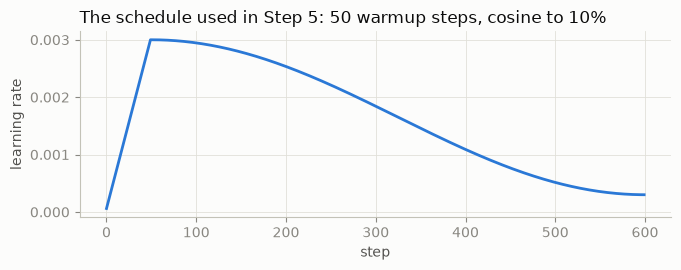

In [7]:
def lr_at(step, max_steps, lr_max, warmup, lr_min_frac=0.1):
    lr_min = lr_max * lr_min_frac
    if step < warmup:
        return lr_max * (step + 1) / warmup
    progress = (step - warmup) / max(1, max_steps - warmup)
    return lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * progress))

steps = np.arange(600)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(steps, [lr_at(s, 600, 3e-3, 50) for s in steps], color=SERIES[0])
ax.set_xlabel("step")
ax.set_ylabel("learning rate")
ax.set_title("The schedule used in Step 5: 50 warmup steps, cosine to 10%", loc="left")
plt.tight_layout()
plt.show()

## Step 4: Gradient clipping

Every now and then one batch produces a very large gradient. Adam's normalisation softens it, but $v$ adapts slowly, so a sudden, much larger gradient still gives a big step. **Clipping by global norm**: compute the length of the whole gradient (all parameters as one long vector), and if it is above a limit, scale everything down to that length.

It changes the length of the step, never its direction. Proof on random gradients:

In [8]:
def clip_grads(P, max_norm):
    # returns the norm before clipping, which is worth logging
    norm = math.sqrt(sum((p.grad**2).sum() for p in P.values()))
    if norm > max_norm:
        for p in P.values():
            p.grad *= max_norm / norm
    return norm

rng = np.random.default_rng(0)
G = {k: Tensor(np.zeros(s)) for k, s in [("a", (4, 5)), ("b", (7,))]}
for p in G.values():
    p.grad = rng.standard_normal(p.shape) * 10
flat = lambda: np.concatenate([p.grad.ravel() for p in G.values()])

g_before = flat()
norm = clip_grads(G, max_norm=1.0)
g_after = flat()
cos = g_before @ g_after / (np.linalg.norm(g_before) * np.linalg.norm(g_after))
print(f"norm before {norm:.2f}, after {np.linalg.norm(g_after):.4f}, cosine between them {cos:.12f}")

norm before 43.56, after 1.0000, cosine between them 1.000000000000


## Step 5: A training run

Everything together:

- batch 32 windows × 128 characters = 4,096 predictions per step;
- AdamW, betas (0.9, 0.99), weight decay 0.1;
- peak lr 3e-3, warmup 50 steps, cosine to 10% (the peak comes from a scout run, below);
- clip the gradient norm at 1.0;
- every 100 steps, the val loss on the same 10 fixed val batches (fixed, so the numbers are comparable between evaluations).

The peak learning rate came from a scout before writing this notebook: 200 steps (50 warmup, then constant) at four learning rates, same model and data:

| peak lr | 3e-4 | 1e-3 | **3e-3** | 1e-2 |
|---|---|---|---|---|
| val loss after 200 steps | 2.52 | 2.41 | **2.32** | 2.46 |
| largest step-to-step jump in train loss | 0.07 | 0.08 | 0.08 | 0.07 |

3e-3 learned fastest, and 1e-2 was already worse. None of them had a loss spike, even 1e-2 (notebook 3 starts from that).

This is a **short** run, 600 steps (~20 minutes), to see the whole loop work and to have a model to sample from. The longer run is `train.py`.

**A memory leak, and the fix.** The first version of this loop ran out of memory (16 GB) after a few steps: memory grew by ~3 GB every step. Every node in the engine's graph keeps a `_backward` closure that points back at the node itself, so each graph is a **reference cycle**. Python frees normal objects as soon as nothing points at them, but cycles only when its cycle collector runs, and that is triggered by how many Python *objects* are created, not by how many bytes. A step creates only ~2,000 nodes, but they hold ~3 GB of arrays. So the training step runs inside a function (its graph becomes garbage when the function returns), followed by `gc.collect()` (~0.1 s, ~5% of a step). Module 2's models were too small for this to show.

In [9]:
import gc

def train_step(P, opt, rng, lr, B=32):
    for p in P.values():
        p.grad = np.zeros_like(p.data)               # grads accumulate in the engine, reset every step
    loss = loss_fn(P, *get_batch(train_data, B, cfg["T"], rng), cfg)
    loss.backward()
    norm = clip_grads(P, 1.0)
    opt.step(lr)
    return float(loss.data), norm

def evaluate(P, data, n_batches=10, B=32, seed=123):
    rng = np.random.default_rng(seed)                # the same batches every time
    losses = []
    for _ in range(n_batches):
        losses.append(float(loss_fn(P, *get_batch(data, B, cfg["T"], rng), cfg).data))
        gc.collect()
    return float(np.mean(losses))

max_steps, warmup, lr_max = 600, 50, 3e-3
P = {k: Tensor(v) for k, v in init_gpt(cfg, np.random.default_rng(0)).items()}
opt = AdamW(P, betas=(0.9, 0.99), weight_decay=0.1)
rng = np.random.default_rng(1)

log = {"loss": [], "norm": [], "lr": [], "val_step": [], "val": []}
t0 = time.perf_counter()
for step in range(max_steps + 1):
    if step % 100 == 0:
        log["val_step"].append(step)
        log["val"].append(evaluate(P, val_data))
        train = f"{np.mean(log['loss'][-100:]):.3f}" if log["loss"] else "  -  "
        print(f"step {step:4d}  train {train}  val {log['val'][-1]:.3f}  [{time.perf_counter() - t0:.0f}s]", flush=True)
    if step == max_steps:
        break
    lr = lr_at(step, max_steps, lr_max, warmup)
    loss, norm = train_step(P, opt, rng, lr)
    gc.collect()                                     # free the graph, see the note above
    log["loss"].append(loss); log["norm"].append(norm); log["lr"].append(lr)

print(f"\n{max_steps} steps in {(time.perf_counter() - t0) / 60:.1f} min")

step    0  train   -    val 4.552  [12s]
step  100  train 2.886  val 2.483  [241s]
step  200  train 2.421  val 2.343  [451s]
step  300  train 2.148  val 2.010  [661s]
step  400  train 1.903  val 1.831  [871s]
step  500  train 1.756  val 1.725  [1082s]
step  600  train 1.666  val 1.674  [1296s]

600 steps in 21.6 min


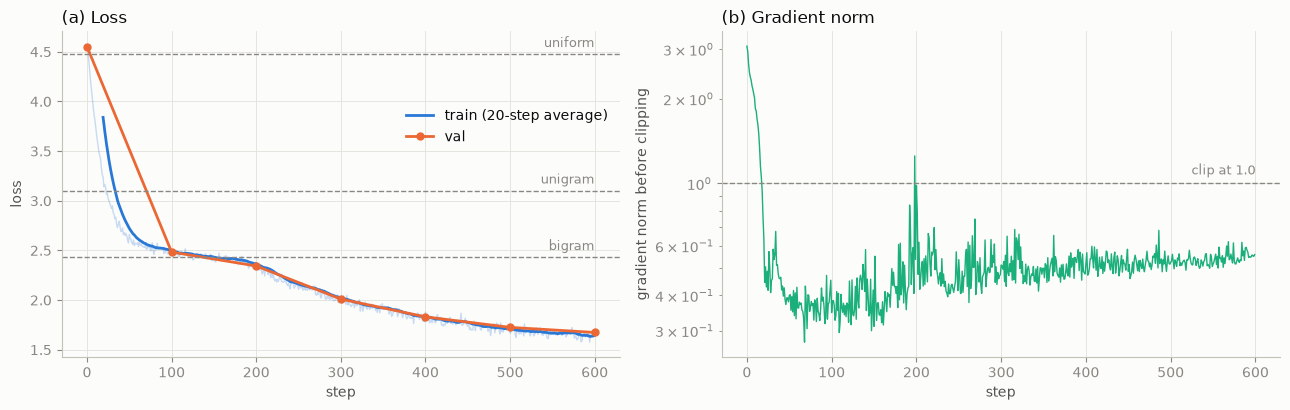

val: step 0 4.552 -> step 600 1.674   (bigram 2.433, unigram 3.103)
steps where the norm was clipped: 3%


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
smooth = np.convolve(log["loss"], np.ones(20) / 20, mode="valid")
ax1.plot(np.arange(len(log["loss"])), log["loss"], color=SERIES[0], alpha=0.25, lw=1)
ax1.plot(np.arange(19, len(log["loss"])), smooth, color=SERIES[0], label="train (20-step average)")
ax1.plot(log["val_step"], log["val"], "o-", color=SERIES[1], ms=5, label="val")
for y, name in [(np.log(V), "uniform"), (UNIGRAM, "unigram"), (BIGRAM, "bigram")]:
    ax1.axhline(y, color=MUTED, ls="--", lw=1)
    ax1.text(len(log["loss"]), y + 0.04, name, color=MUTED, fontsize=9, ha="right", va="bottom")
ax1.set_xlabel("step")
ax1.set_ylabel("loss")
ax1.set_title("(a) Loss", loc="left")
ax1.legend(loc="upper right", bbox_to_anchor=(1, 0.8))

ax2.plot(log["norm"], color=SERIES[2], lw=1)
ax2.axhline(1.0, color=MUTED, ls="--", lw=1)
ax2.text(len(log["norm"]), 1.05, "clip at 1.0", color=MUTED, fontsize=9, ha="right", va="bottom")
ax2.set_yscale("log")
ax2.set_xlabel("step")
ax2.set_ylabel("gradient norm before clipping")
ax2.set_title("(b) Gradient norm", loc="left")
plt.tight_layout()
plt.show()

print(f"val: step 0 {log['val'][0]:.3f} -> step {log['val_step'][-1]} {log['val'][-1]:.3f}   "
      f"(bigram {BIGRAM}, unigram {UNIGRAM})")
print(f"steps where the norm was clipped: {np.mean(np.array(log['norm']) > 1.0):.0%}")

**Val loss 4.55 → 1.67 in 600 steps**, well below the bigram's 2.43. Three phases are visible in (a):

1. **steps 0 – ~80**: a fast drop to ~2.5. That is about what the bigram gets, so the model has learned character frequencies and which character tends to follow which.
2. **~100 – 200**: a plateau around the bigram line (val 2.48 → 2.34). Looking only at the previous character is as far as it gets for a while.
3. **from ~200**: it falls again, 2.34 → 1.67. Beating the bigram by this much means it is using the earlier characters in the context, which is the attention layers' job. In (b), the one jump in the gradient norm after warmup is right where this phase starts. (That attention is what changed is my reading of the curve. I haven't measured it.)

Train and val stay together (1.666 vs 1.674), so no overfitting yet, after the model has seen the training text about 5 times (600 × 4,096 ≈ 2.5M predictions vs 506K training characters). Clipping fired on 3% of the steps, nearly all of them in the first ~20, where the norm starts at 3.

## Step 6: Sampling

The model outputs a probability for every next character. Generating text is a loop: run the model on the text so far, pick a character from its distribution, append it, repeat. *How* to pick is a choice:

| method | what it does |
|---|---|
| **greedy** (temperature 0) | always the most likely character. Deterministic, and tends to loop |
| **temperature** $\tau$ | divide the logits by $\tau$ before softmax. $\tau < 1$ sharpens, $\tau > 1$ flattens |
| **top-k** | keep only the $k$ most likely characters, renormalise |
| **top-p** (nucleus) | keep the smallest set of characters whose probability adds up to at least $p$, renormalise |

First, each filter on a small distribution where the right answer can be checked by hand:

In [11]:
def next_probs(logits, temperature=1.0, top_k=None, top_p=None):
    if temperature == 0:
        p = np.zeros_like(logits)
        p[np.argmax(logits)] = 1.0
        return p
    z = logits / temperature
    if top_k is not None:
        z = np.where(z < np.sort(z)[-top_k], -np.inf, z)
    p = np.exp(z - z.max())
    p /= p.sum()
    if top_p is not None:
        order = np.argsort(-p)
        mass_before = np.cumsum(p[order]) - p[order]
        keep = order[mass_before < top_p]           # keep adding tokens until the mass reaches top_p
        q = np.zeros_like(p)
        q[keep] = p[keep]
        p = q / q.sum()
    return p

logits = np.array([2.0, 1.0, 0.5, 0.0, -1.0, -3.0])
np.set_printoptions(precision=3, suppress=True)
for kw in [{}, {"temperature": 0.5}, {"temperature": 2.0}, {"temperature": 0},
           {"top_k": 3}, {"top_p": 0.9}, {"top_p": 0.5}]:
    print(f"{str(kw):22s} {next_probs(logits, **kw)}")

{}                     [0.561 0.206 0.125 0.076 0.028 0.004]
{'temperature': 0.5}   [0.829 0.112 0.041 0.015 0.002 0.   ]
{'temperature': 2.0}   [0.363 0.22  0.172 0.134 0.081 0.03 ]
{'temperature': 0}     [1. 0. 0. 0. 0. 0.]
{'top_k': 3}           [0.629 0.231 0.14  0.    0.    0.   ]
{'top_p': 0.9}         [0.579 0.213 0.129 0.078 0.    0.   ]
{'top_p': 0.5}         [1. 0. 0. 0. 0. 0.]


Check by hand:

- **temperature 0.5 / 2.0**: the same order, sharper / flatter; at 0, all mass on the top character.
- **top-k 3**: exactly 3 characters left, and their ratios are unchanged (0.561 : 0.206 : 0.125 = 0.629 : 0.231 : 0.140).
- **top-p 0.9**: the running total of the sorted probabilities is 0.561, 0.767, 0.892, 0.968. The first time it reaches 0.9 is at the 4th character, so 4 are kept. **top-p 0.5**: the top character alone has 0.561 ≥ 0.5, so only it is kept.

## Step 7: Text from the model

Each new character re-runs the model on the whole context (up to 128 characters), which is wasteful: everything but the last position was already computed for the previous character. Fixing that is the KV cache, Module 4.

In [12]:
def generate(P, prompt, n, rng, **kw):
    ids = list(encode(prompt))
    for i in range(n):
        ctx = np.array(ids[-cfg["T"]:])[None]          # the model only has 128 positions
        logits = gpt(P, ctx, cfg).data[0, -1]
        ids.append(rng.choice(V, p=next_probs(logits, **kw)))
        if i % 50 == 49:
            gc.collect()                               # every forward pass leaves a graph behind too
    return decode(ids)

prompt = "Holmes"
for kw in [{"temperature": 0}, {"temperature": 1.0}, {"temperature": 0.8, "top_k": 20}, {"temperature": 1.0, "top_p": 0.9}]:
    t0 = time.perf_counter()
    out = generate(P, prompt, 300, np.random.default_rng(0), **kw)
    print(f"===== {kw}  ({time.perf_counter() - t0:.1f}s)")
    print(out)
    print()

===== {'temperature': 0}  (10.9s)
Holmes, and the was was a little the state of the state of the
stance of the should be of the state of the state of the state of the
stept of the state of the state of the state of the state of the stept
the spect of the stare of the state of the state of the state of the she
stept of the stare of the sta

===== {'temperature': 1.0}  (9.7s)
Holmes, I
to thou unsit. I blingysely but myself miss, there cloce, Mr. Holmes when’t
she his brow turesten to mer to saway the whent ack, hand well-bit the
has puls finut exscevedasity-thaore very jewhatter seent life the louse
ast boooked of rugning to they, drating-edge. 
“Welly, you whook, I are scris

===== {'temperature': 0.8, 'top_k': 20}  (9.8s)
Holmes, I
to thin the very botinuth. I shall mone nother fread, and and from
who hesurned his bitterst with the lodge tates the weekn about indew son
such take found his sherp hunds, with all how difes,
to have no is gave think a spect the booses with st up, then the

After 20 minutes of training:

- **greedy** gets stuck in a loop ("the state of the state of the ..."). The most likely next character keeps leading back into the same phrase. This is why nobody samples greedily from a language model;
- **sampled** text has the shape of the book: lines of ~70 characters, dialogue in curly quotes, "Mr. Holmes", commas and full stops in sensible places, and many real short words (*to, the, his, with, there, myself*), but also plenty of invented ones (*exscevedasity*);
- the three sampled versions all start the same way ("Holmes, I / to th..."): they use the same random seed, and for the first few characters the filters barely change the distribution;
- each 300-character sample takes ~10 s, because every character re-runs the whole context (Module 4).

At 1.67 the model knows spelling and layout, but not sentences. That needs more training: the full run in `train.py`.

## Summary

- **AdamW by hand**, proved on two cases: the first step is exactly lr for every parameter whatever its gradient size, and decoupled decay shrinks every weight by the same factor, which L2 inside Adam does not.
- **Warmup + cosine schedule, global-norm clipping** (direction unchanged, cosine 1.0 to 12 digits).
- **A memory leak in the engine's graph** (reference cycles holding ~3 GB per step), fixed with `gc.collect()` after each step.
- **20 minutes of training**: val loss 4.55 → 1.67, against 2.43 for the bigram, with no overfitting yet.
- **Sampling**: greedy loops; temperature / top-k / top-p give text with the book's shape and many real words.

## Next: Notebook 3, the experiment

Why is warmup needed at all? Without it, training at a high learning rate gets stuck at the unigram loss. Notebook 3 measures what goes wrong inside the model and tests the cause. It also re-runs the √d comparison from Module 2 with Adam instead of plain SGD, as promised there.